In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)  # don't truncate long cell contents

In [2]:
import re
from concurrent.futures import ThreadPoolExecutor
from glob import glob
from os.path import basename, dirname

# ---------------------------------------------------------------- parsing ---

_FIELD_RE = re.compile(r"^\s*([A-Za-z][^:]*?)\s*:\s*(.*?)\s*$")
_MISSING = {"", "-", "n/a", "na", "none", "null"}


def _to_bool(v):
    return v.strip().lower() in {"yes", "true", "1"}


def _to_seconds(v):
    return float(v.split()[0])


# report label -> (dict key, caster)
_FIELDS = {
    "Item Index":                          ("item_index", int),
    "JSON Path":                           ("json_path", str),
    "Embedding Path":                      ("embedding_path", str),
    "JSON Valid":                          ("json_valid", _to_bool),
    "Sequence Similarity (Gestalt)*":      ("sequence_similarity", float),
    "Levenshtein Distance (minified)":     ("levenshtein_distance", int),
    "Levenshtein Similarity (minified)*":  ("levenshtein_similarity", float),
    "App Match":                           ("app_match", _to_bool),
    "Activity Match":                      ("activity_match", _to_bool),
    "Component Count (GT)":                ("component_count_gt", int),
    "Component Count (Pred)":              ("component_count_pred", int),
    "Class Accuracy*":                     ("class_accuracy", float),
    "Average Bounds IoU*":                 ("average_bounds_iou", float),
    "Execution Time":                      ("execution_time", _to_seconds),
}


def parse_metrics_from_report_file(path):
    """Parse an evaluation report into a flat dict of metrics.

    The side-by-side JSON dump is skipped entirely; missing or unparsable
    values become None so every report yields the same set of keys.
    """
    with open(path, "r", encoding="utf-8", errors="replace") as fh:
        text = fh.read()

    # header (above the JSON table) + everything below "METRICS:"
    head, sep, tail = text.partition("GROUND TRUTH")
    relevant = head + tail.partition("METRICS:")[2] if sep else text

    out = {key: None for key, _ in _FIELDS.values()}
    for line in relevant.splitlines():
        match = _FIELD_RE.match(line)
        if match is None:
            continue
        label, raw = match.group(1), match.group(2)
        if label not in _FIELDS:
            continue
        key, cast = _FIELDS[label]
        if raw.lower() in _MISSING:
            continue
        try:
            out[key] = cast(raw)
        except (ValueError, IndexError):
            out[key] = None
    return out


def _process_report(g):
    # e.g. "reconstructions_4096_avg/0_report.txt" -> "4096_avg"
    # e.g. "reconstructions_4096_last/0_report.txt" -> "4096_last"
    # keeping the pooling suffix (avg/last) in the key prevents the
    # 4096_avg and 4096_last folders from clobbering each other.
    dimensions = dirname(g).removeprefix("reconstructions_")
    idx = basename(g).split("_")[0]
    return (dimensions, idx), parse_metrics_from_report_file(g)


# ------------------------------------------------------------------- entry ---

def parse_reconstruction_dataset(pattern="reconstructions*/*", max_workers=None):
    """Glob reconstruction report files and parse them in parallel.

    Returns a dict keyed by (dimensions, idx) -> metrics dict.
    """
    paths = [g for g in glob(pattern) if "report" in g]

    results = {}
    with ThreadPoolExecutor(max_workers=max_workers) as pool:
        for key, metrics in pool.map(_process_report, paths, chunksize=8):
            results[key] = metrics

    return results

In [3]:
results = parse_reconstruction_dataset()

df = pd.DataFrame(results).T
df.index.names = ['dim', 'idx']

## Filters

In [4]:
# keep only same indices among all samples
# idx_per_dim = df.index.to_frame(index=False).groupby('dim')['idx'].apply(set)
# common_idx = set.intersection(*idx_per_dim)
# df = df.loc[df.index.get_level_values('idx').isin(common_idx)]

# remove overtrained adapter
#df = df[(df.index.get_level_values('dim') != '128x4096_avg')]

# Take only validation set jsons into account
#df = df[(df.index.get_level_values('idx').astype(int) > 11504)]

# Take only valid jsons into account across all dimensions
# df = df[df.groupby(level='idx')['json_valid'].transform('all')]

In [5]:
df

item_index  \
dim                                                          idx                
128x4096_avg                                                 0              0   
                                                             10000      10000   
                                                             10002      10002   
                                                             10003      10003   
                                                             10004      10004   
...                                                                       ...   
for_adapter_model_out_embeddings_4096_last_full_qwen2.5-1.5b 997          997   
                                                             998          998   
                                                             999          999   
                                                             99            99   
                                                             9              9   

                                                                                               json_path  \
dim                                                          idx                                           
128x4096_avg                                                 0          ../rico-data/data/layouts/0.json   
                                                             10000  ../rico-data/data/layouts/10000.json   
                                                             10002  ../rico-data/data/layouts/10002.json   
                                                             10003  ../rico-data/data/layouts/10003.json   
                                                             10004  ../rico-data/data/layouts/10004.json   
...                                                                                                  ...   
for_adapter_model_out_embeddings_4096_last_full_qwen2.5-1.5b 997      ../rico-data/data/layouts/997.json   
                                                             998      ../rico-data/data/layouts/998.json   
                                                             999      ../rico-data/data/layouts/999.json   
                                                             99        ../rico-data/data/layouts/99.json   
                                                             9          ../rico-data/data/layouts/9.json   

                                                                                       embedding_path  \
dim                                                          idx                                        
128x4096_avg                                                 0          embeddings_128x4096_avg/0.npz   
                                                             10000  embeddings_128x4096_avg/10000.npz   
                                                             10002  embeddings_128x4096_avg/10002.npz   
                                                             10003  embeddings_128x4096_avg/10003.npz   
                                                             10004  embeddings_128x4096_avg/10004.npz   
...                                                                                               ...   
for_adapter_model_out_embeddings_4096_last_full_qwen2.5-1.5b 997         embeddings_4096_last/997.npz   
                                                             998         embeddings_4096_last/998.npz   
                                                             999         embeddings_4096_last/999.npz   
                                                             99           embeddings_4096_last/99.npz   
                                                             9             embeddings_4096_last/9.npz   

                                                                   json_valid  \
dim                                                          idx                
128x4096_avg                                                 0           True   

In [6]:
df.columns

Index(['item_index', 'json_path', 'embedding_path', 'json_valid',
       'sequence_similarity', 'levenshtein_distance', 'levenshtein_similarity',
       'app_match', 'activity_match', 'component_count_gt',
       'component_count_pred', 'class_accuracy', 'average_bounds_iou',
       'execution_time'],
      dtype='str')

In [7]:
df.groupby("dim").count()

,item_index,json_path,embedding_path,json_valid,sequence_similarity,levenshtein_distance,levenshtein_similarity,app_match,activity_match,component_count_gt,component_count_pred,class_accuracy,average_bounds_iou,execution_time
dim,,,,,,,,,,,,,,
128x4096_avg,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927
16x4096_avg,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
32x4096_avg,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
4x4096_avg,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
64x4096_avg,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
8x4096_avg,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
for_adapter_model_out_embeddings_4096_last_full_qwen2.5-1.5b,7682,7682,7682,7682,7682,7682,7682,7682,7682,7682,7682,7682,7682,7682


In [16]:
def show_stats(column: str):
    global df
    df[column] = pd.to_numeric(df[column], errors='coerce')
    df.boxplot(column=column, by='dim', showfliers=False, figsize=(8,6))
    plt.xticks(rotation=45)

    # Deskriptive Statistiken pro Gruppe
    desc_stats = df.groupby('dim')[column].describe()
    desc_stats['median'] = df.groupby('dim')[column].median()
    desc_stats['IQR'] = df.groupby('dim')[column].quantile(0.75) - df.groupby('dim')[column].quantile(0.25)
    print(desc_stats)

def plot_bool_grouped(df: pd.DataFrame, bool_cols: list, by: str, as_percentage: bool = True):
    """
    Plottet den Anteil von True für mehrere Spalten gruppiert nach einer Kategorie.

    :param df: Pandas DataFrame
    :param bool_cols: Liste der True/False-Spalten
    :param by: Spaltenname oder Index-Level für die Gruppierung (z.B. 'dim')
    :param as_percentage: True für Prozent (0-100%), False für absolute Anzahl
    """
    # Falls 'by' im Index liegt, den Index auflösen
    data = df.reset_index() if (by in df.index.names and by not in df.columns) else df.copy()

    if as_percentage:
        grouped = data.groupby(by)[bool_cols].mean() * 100
        errors = data.groupby(by)[bool_cols].sem() * 100
        ylabel = 'Anteil True (%)'
    else:
        grouped = data.groupby(by)[bool_cols].sum()
        errors = data.groupby(by)[bool_cols].std()
        ylabel = 'Anzahl True'

    ax = grouped.plot(kind='bar', capsize=4, figsize=(8, 6))

    for container in ax.containers:
        ax.bar_label(container, fmt='%.1f' if as_percentage else '%.0f', padding=3, fontsize=8)

    plt.ylabel(ylabel)
    plt.xlabel(by)
    plt.title(f'True-Verteilung gruppiert nach "{by}"')
    plt.xticks(rotation=45)
    plt.legend(title='Spalten', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

In [17]:
df.groupby('dim').count()

,item_index,json_path,embedding_path,json_valid,sequence_similarity,levenshtein_distance,levenshtein_similarity,app_match,activity_match,component_count_gt,component_count_pred,class_accuracy,average_bounds_iou,execution_time
dim,,,,,,,,,,,,,,
128x4096_avg,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927,46927
16x4096_avg,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
32x4096_avg,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
4x4096_avg,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
64x4096_avg,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
8x4096_avg,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000,2000
for_adapter_model_out_embeddings_4096_last_full_qwen2.5-1.5b,7682,7682,7682,7682,7682,7682,7682,7682,7682,7682,7682,7682,7682,7682


In [ ]:
file_counts = pd.Series({
    d.removeprefix("reconstructions_"): len(glob(f"{d}/*")) // 2
    for d in glob("reconstructions_*")
}).sort_index()

ax = file_counts.plot(kind='bar', figsize=(8, 6), legend=False)
ax.bar_label(ax.containers[0], fmt='%.0f', padding=3, fontsize=8)
plt.ylabel('Anzahl Items (Dateien / 2)')
plt.xlabel('dim')
plt.title('Anzahl Items pro "dim" (aus Dateisystem, ungefiltert)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plot_bool_grouped(df, ['json_valid'], by="dim", as_percentage=False)
plot_bool_grouped(df, ['app_match'], by="dim", as_percentage=False)
plot_bool_grouped(df, ['activity_match'], by="dim", as_percentage=False)

                                                                count  \
dim                                                                     
128x4096_avg                                                  46927.0   
16x4096_avg                                                    2000.0   
32x4096_avg                                                    2000.0   
4x4096_avg                                                     2000.0   
64x4096_avg                                                    2000.0   
8x4096_avg                                                     2000.0   
for_adapter_model_out_embeddings_4096_last_full_qwen2.5-1.5b   7682.0   

                                                                  mean  \
dim                                                                      
128x4096_avg                                                  0.336688   
16x4096_avg                                                   0.096055   
32x4096_avg                                   

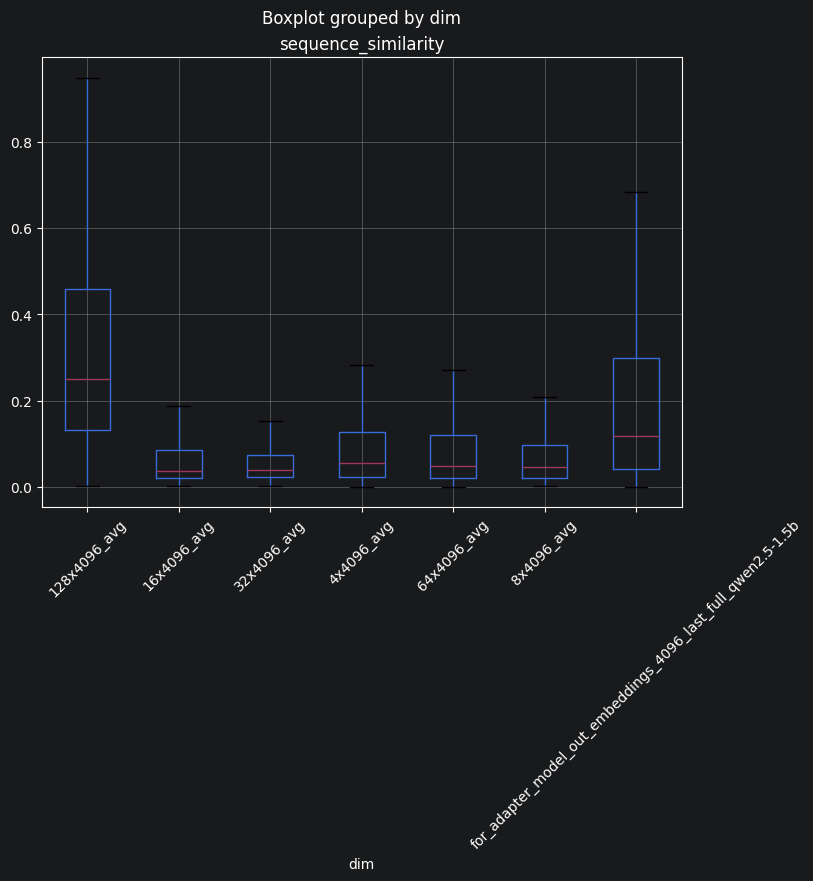

In [11]:
show_stats('sequence_similarity')

                                                                count  \
dim                                                                     
128x4096_avg                                                  46927.0   
16x4096_avg                                                    2000.0   
32x4096_avg                                                    2000.0   
4x4096_avg                                                     2000.0   
64x4096_avg                                                    2000.0   
8x4096_avg                                                     2000.0   
for_adapter_model_out_embeddings_4096_last_full_qwen2.5-1.5b   7682.0   

                                                                      mean  \
dim                                                                          
128x4096_avg                                                   1549.240054   
16x4096_avg                                                   17414.524500   
32x4096_avg                   

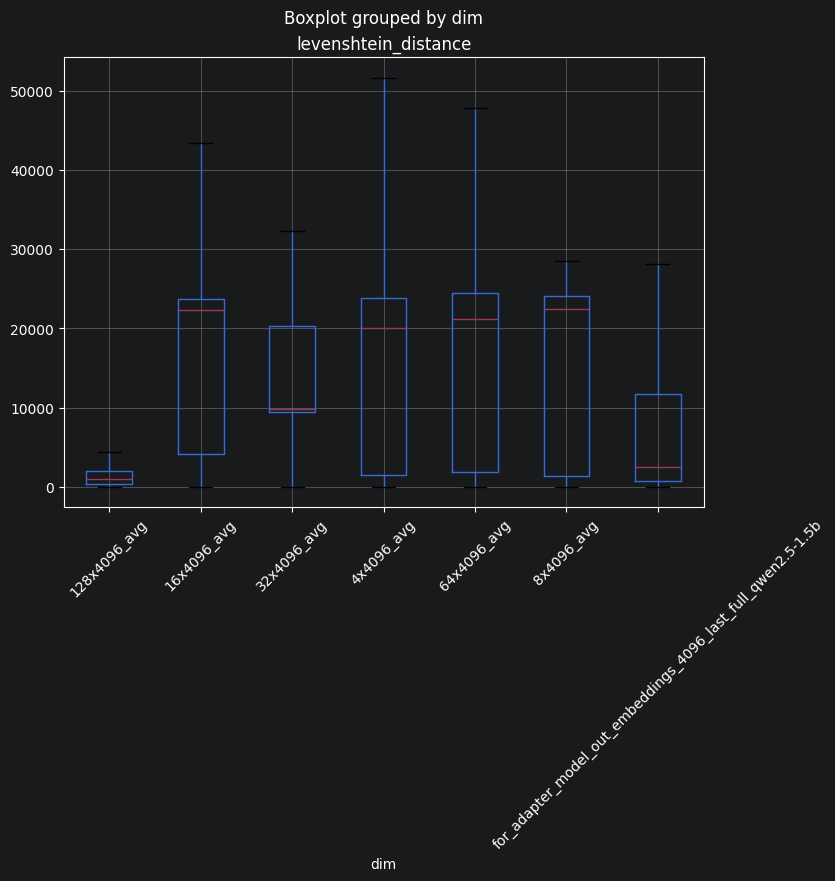

In [12]:
show_stats('levenshtein_distance')

                                                                count  \
dim                                                                     
128x4096_avg                                                  46927.0   
16x4096_avg                                                    2000.0   
32x4096_avg                                                    2000.0   
4x4096_avg                                                     2000.0   
64x4096_avg                                                    2000.0   
8x4096_avg                                                     2000.0   
for_adapter_model_out_embeddings_4096_last_full_qwen2.5-1.5b   7682.0   

                                                                  mean  \
dim                                                                      
128x4096_avg                                                  0.577837   
16x4096_avg                                                   0.189945   
32x4096_avg                                   

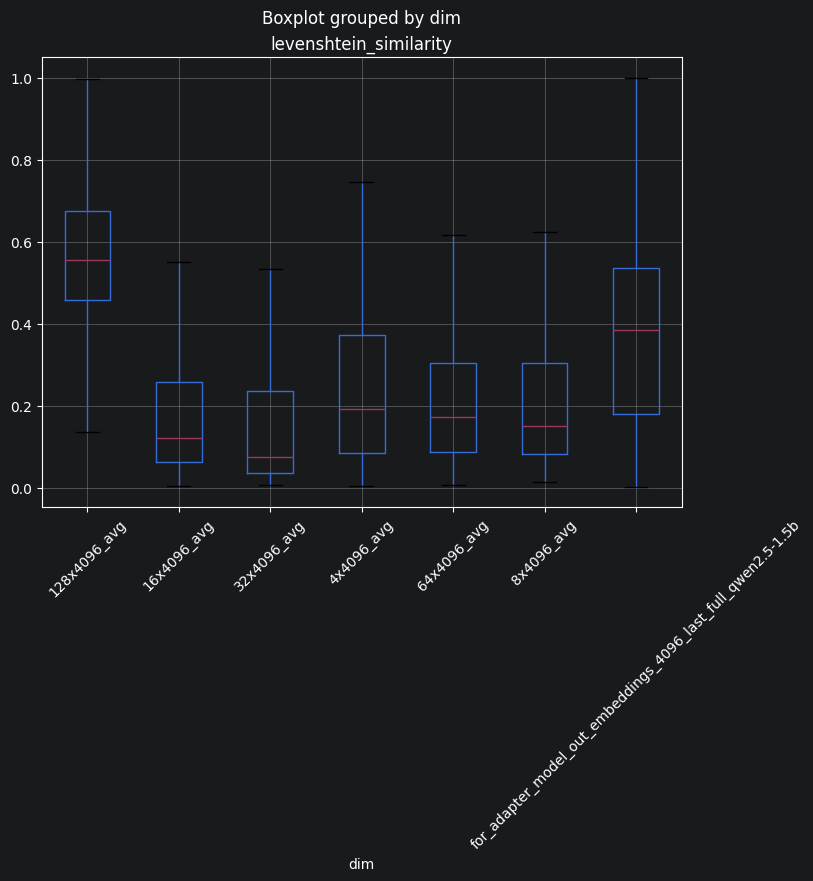

In [13]:
show_stats('levenshtein_similarity')

                                                                count  \
dim                                                                     
128x4096_avg                                                  46927.0   
16x4096_avg                                                    2000.0   
32x4096_avg                                                    2000.0   
4x4096_avg                                                     2000.0   
64x4096_avg                                                    2000.0   
8x4096_avg                                                     2000.0   
for_adapter_model_out_embeddings_4096_last_full_qwen2.5-1.5b   7682.0   

                                                                  mean  \
dim                                                                      
128x4096_avg                                                  0.347687   
16x4096_avg                                                   0.052214   
32x4096_avg                                   

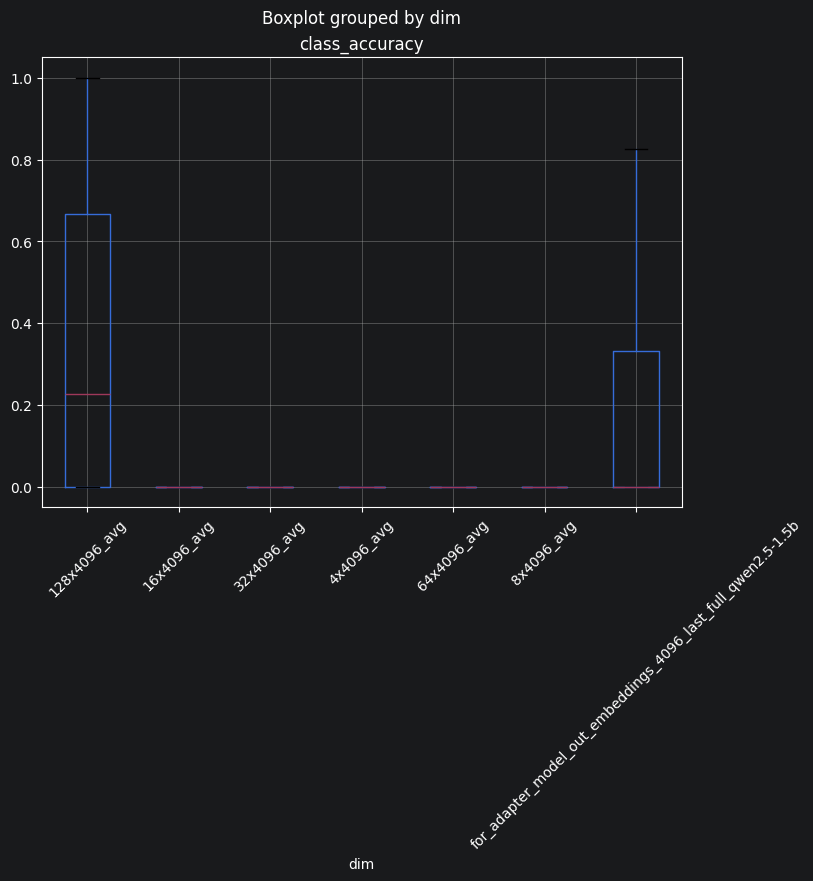

In [14]:
show_stats('class_accuracy')

                                                                count  \
dim                                                                     
128x4096_avg                                                  46927.0   
16x4096_avg                                                    2000.0   
32x4096_avg                                                    2000.0   
4x4096_avg                                                     2000.0   
64x4096_avg                                                    2000.0   
8x4096_avg                                                     2000.0   
for_adapter_model_out_embeddings_4096_last_full_qwen2.5-1.5b   7682.0   

                                                                  mean  \
dim                                                                      
128x4096_avg                                                  0.211662   
16x4096_avg                                                   0.057904   
32x4096_avg                                   

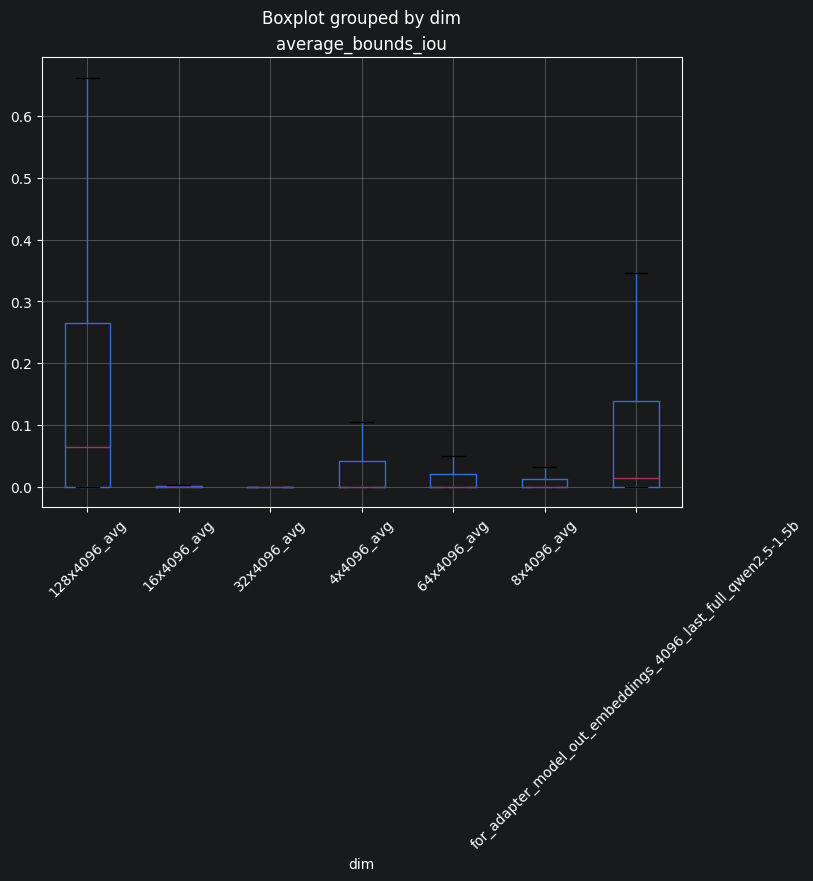

In [15]:
show_stats('average_bounds_iou')